# Stabilità rispetto a C — plot

Correlazione fra le grandezze calcolate con perturbazione (rewiring) della matrice di composizione C (intensità η) e quelle a η = 0.
Legge `results/stability/C/{ALGO}/C_stability_{res}_digits.parquet`,
prodotti da `notebooks/data_generation/C_stability.ipynb`.

Per ogni algoritmo e risoluzione (4 e 6 digits, stesso asse y per affiancarle) due figure:
1. Q, CQ, Δ
2. F, S (S = import penalty)

Colore = grandezza; linea piena = Pearson, tratteggiata = Spearman.
A η = 0 tutte le correlazioni devono valere 1: il notebook lo controlla.
Figure in PDF in `figures/stability/C/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)
from src.plotting import load_stability, check_eta0, plot_stability, plot_corr_vs_order

set_style()

In [2]:
TARGET = "C"
RESOLUTIONS = [4, 6]
GROUPS = {
    "Q_CQ_Delta": ["Q", "CQ", "Delta"],
    "F_S":        ["F", "S"],
}

SAVE_FIGS = True

# Scala y fissa per tutte le figure di stabilita', cosi' sono confrontabili fra loro
# (correlazioni vicine a 1 = metrica stabile). Eccezioni in OVERRIDES.
YLIM = (-0.05, 1.03)
FIG_DIR = ROOT / "plots" / "stability" / TARGET

# Ritocchi per singola figura, dove la legenda automatica copre le curve:
# (algo, gruppo) -> {"ylim": (min, max), "legend": {kwargs di ax.legend}}
OVERRIDES = {}

## extended_eci_with_imports

Q_CQ_Delta — 4 digits


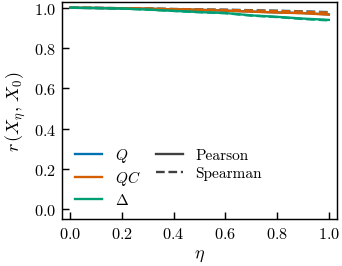

Q_CQ_Delta — 6 digits


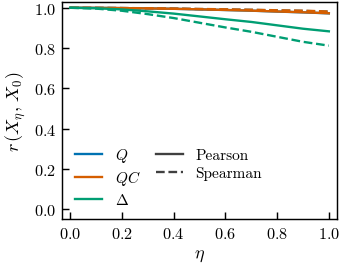

F_S — 4 digits


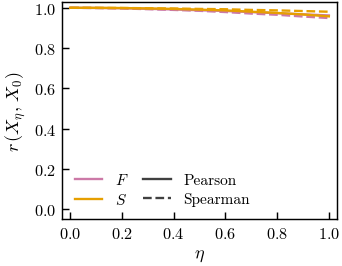

F_S — 6 digits


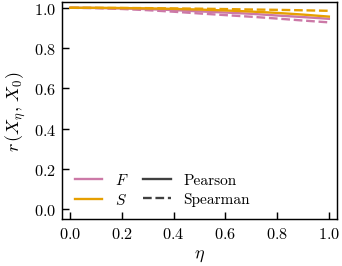

In [3]:
algo = "extended_eci_with_imports"
tables = load_stability(TARGET, algo, RESOLUTIONS)
check_eta0(tables, [q for qs in GROUPS.values() for q in qs])

for name, quantities in GROUPS.items():
    cols = [f"{m}_{q}" for q in quantities for m in ("pearson", "spearman")]
    ov = OVERRIDES.get((algo, name), {})
    ylim = ov.get("ylim") or YLIM
    for res, df in tables.items():
        print(f"{name} — {res} digits")
        plot_stability(df, quantities, ylim=ylim, legend_kw=ov.get("legend"),
                       save_path=FIG_DIR / f"{algo}_{name}_{res}_digits" if SAVE_FIGS else None)

## extended_fitness_with_imports

Q_CQ_Delta — 4 digits


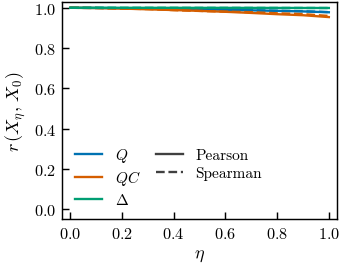

Q_CQ_Delta — 6 digits


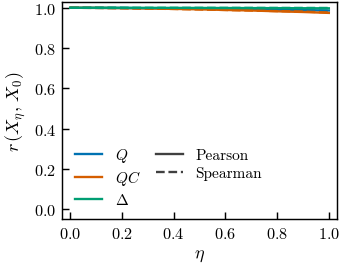

F_S — 4 digits


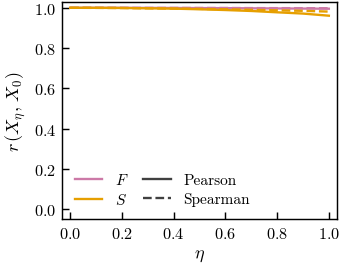

F_S — 6 digits


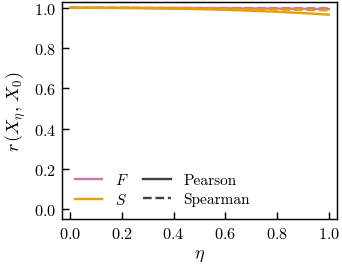

In [4]:
algo = "extended_fitness_with_imports"
tables = load_stability(TARGET, algo, RESOLUTIONS)
check_eta0(tables, [q for qs in GROUPS.values() for q in qs])

for name, quantities in GROUPS.items():
    cols = [f"{m}_{q}" for q in quantities for m in ("pearson", "spearman")]
    ov = OVERRIDES.get((algo, name), {})
    ylim = ov.get("ylim") or YLIM
    for res, df in tables.items():
        print(f"{name} — {res} digits")
        plot_stability(df, quantities, ylim=ylim, legend_kw=ov.get("legend"),
                       save_path=FIG_DIR / f"{algo}_{name}_{res}_digits" if SAVE_FIGS else None)